# California Proposition 99

Cigarette consumption, 1970–2000; first affected year 1989. Outcome: cigarette packs per capita.

The SDID reference is −15.6038278727 packs per person. This is the no-covariate example in Arkhangelsky et al. (2021), [AER](https://doi.org/10.1257/aer.20190159), using the tobacco-control setting of Abadie, Diamond and Hainmueller (2010), [JASA](https://doi.org/10.1198/jasa.2009.ap08746). The latter's covariate-based SCM specification is **not** reproduced by the outcome-only SCM row below.

Run from a checkout installed using `requirements-replication.txt` and `pip install -e .`. The notebook downloads immutable public data with **requests**, checks the reference specification, and exports three publication figures as PDF, SVG and 300 dpi PNG. See [the replication guide](../docs/replication.md) and [the figure guide](../docs/plotting.md).

In [1]:
%matplotlib inline
import hashlib
from dataclasses import replace
import os
from io import BytesIO
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from pysynth import (
    SyntheticControl, SCUL, IndividualSC, TwoStageIndividualSC,
    SyntheticDID, DifferenceInDifferences, PySyncon, SCM, compare,
    plot_paths, plot_effects, plot_comparison, save_figure,
)
from pysynth.datasets import DATASETS
from pysynth.replication import LITERATURE_BENCHMARKS, replicate, check_replication

pd.Series({p: version(p) for p in [
    'pysynth-control', 'numpy', 'scipy', 'pandas', 'matplotlib',
    'pysyncon', 'SyntheticControlMethods',
]}, name='version')

pysynth-control             0.1.0
numpy                       2.0.2
scipy                      1.13.1
pandas                      2.3.3
matplotlib                  3.9.4
pysyncon                    1.7.0
SyntheticControlMethods    1.1.17
Name: version, dtype: object

## Download and verify the academic data

The URL names an immutable upstream commit. SHA256 verification fails
visibly if the bytes differ. No manual download or bundled data is required.

In [2]:
name = 'california'
spec = DATASETS[name]
response = requests.get(spec.url, timeout=30)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == spec.sha256
data = pd.read_csv(BytesIO(response.content), sep=spec.separator)
panel = spec.panel(data)
print(spec.citation)
print(spec.url)
print(f'{panel.n_control} donors; {panel.n_pre} pre-periods; {panel.n_post} post-periods')
data.head()

Abadie, Diamond & Hainmueller (2010), doi:10.1198/jasa.2009.ap08746; Arkhangelsky et al. (2021), doi:10.1257/aer.20190159
https://raw.githubusercontent.com/synth-inference/synthdid/70c1ce3eac58e28c30b67435ca377bb48baa9b8a/data/california_prop99.csv
38 donors; 19 pre-periods; 12 post-periods


,State,Year,PacksPerCapita,treated
0,Alabama,1970,89.800003,0
1,Arkansas,1970,100.300003,0
2,Colorado,1970,124.800003,0
3,Connecticut,1970,120.000000,0
4,Delaware,1970,155.000000,0


## Reference specification and numerical check

This uses the historical specification above. Its numerical assertion is
separate from the new-method comparison. The path figure identifies the
reference estimator explicitly. See `pysynth.replication.replicate` for
predictor windows and optimization settings.

The warm-toned annotation gives the source-reported result at its stated
precision, with a source link and specification context. It is separate
from the numerical replication check. See the
[benchmark provenance](../docs/replication.md#literature-annotations)
for the paper/author-example distinction, compatible units, and the
German paper's 2025 erratum.

/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/replication.py:59: RuntimeWarning: SDID reached max_iter before the objective-decrease stopping rule
  return SyntheticDID().fit(panel)


source                R synthdid reference ATT (paper reports -15.6)
estimate                                                  -15.603828
reference                                                 -15.603828
absolute_tolerance                                          0.000001
Name: Replication check, dtype: object

**Download figure:** [PDF](figures/california/california-reference.pdf) · [SVG](figures/california/california-reference.svg) · [PNG](figures/california/california-reference.png)

**Literature source:** [Arkhangelsky et al. (2021), Table 1 · 1989–2000](https://arxiv.org/pdf/1812.09970v4#page=8)

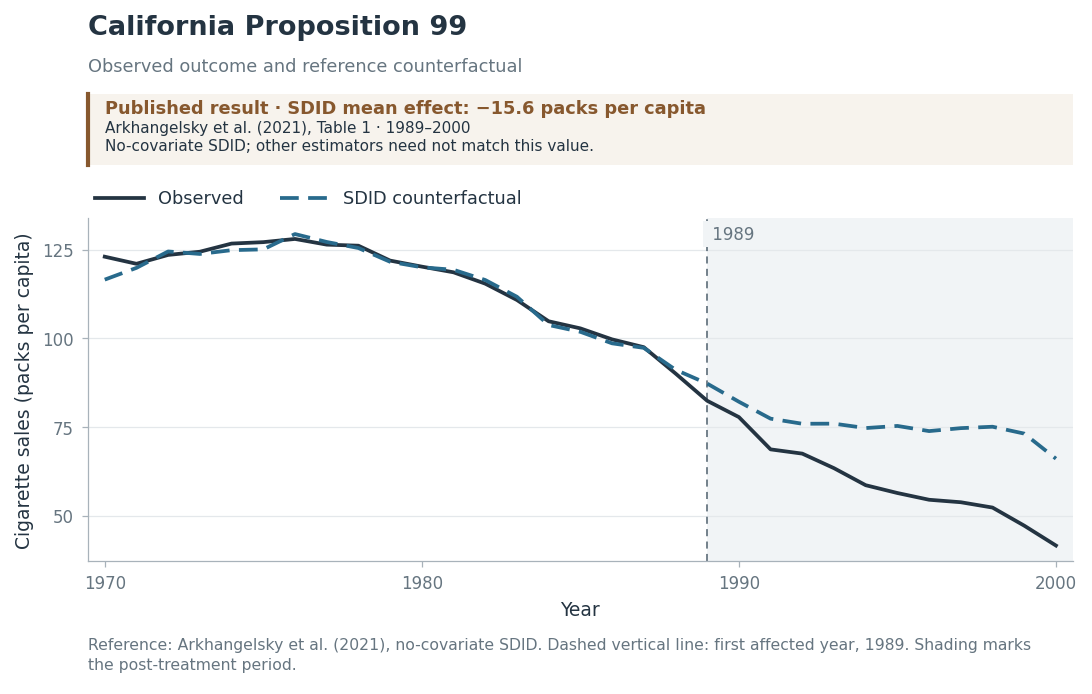

In [3]:
figure_details = {'case': 'California Proposition 99', 'outcome': 'Cigarette sales (packs per capita)', 'effect': 'Effect on cigarette sales (packs per capita)', 'units': 'packs per capita', 'periods': '1970–1988 pretreatment · 1989–2000 post-treatment · 38 donors', 'onset': '1989', 'reference': 'SDID counterfactual', 'reference_note': 'Reference: Arkhangelsky et al. (2021), no-covariate SDID. Dashed vertical line: first affected year, 1989. Shading marks the post-treatment period.'}
benchmark = LITERATURE_BENCHMARKS[name]
# Works when the kernel starts in either the repository or notebook folder.
example_dir = Path.cwd() if Path.cwd().name == 'empirical_examples' else Path.cwd() / 'empirical_examples'
figure_dir = Path(os.environ.get('PYSYNTH_FIGURE_DIR', example_dir / 'figures')) / name

def export_figure(fig, kind):
    paths = save_figure(fig, figure_dir / f'{name}-{kind}')
    links = ' · '.join(
        f'[{p.suffix[1:].upper()}](figures/{name}/{p.name})' for p in paths
    )
    display(Markdown('**Download figure:** ' + links))
    display(Markdown(f'**Literature source:** [{benchmark.citation}]({benchmark.source_url})'))
    return paths

reference = replicate(name, data)
report = check_replication(name, reference)
display(pd.Series(report, name='Replication check'))
ax = plot_paths(
    reference,
    title=figure_details['case'],
    subtitle='Observed outcome and reference counterfactual',
    ylabel=figure_details['outcome'], xlabel='Year',
    observed_label='Observed',
    counterfactual_label=figure_details['reference'],
    intervention_label=figure_details['onset'],
    benchmark=benchmark,
    note=figure_details['reference_note'],
)
reference_files = export_figure(ax.figure, 'reference')
plt.show()

## Fit all applicable methods on a common sample

Every comparison uses the same outcome panel, eligible donors and treatment
date. The native SCM assigns equal importance to pre-outcome periods;
the pysyncon SCM comparison fixes predictor importance after row scaling.
The SyntheticControlMethods adapter uses one initialization and at most
ten evenly spaced outcome-lag predictors plus the outcome mean. Penalized
and robust SCM use the illustrative tuning values shown below. SCUL selects
its penalty by rolling validation within the pretreatment period.

**ISC and 2SISC here use a fixed matching metric, without MSCMT's outer
predictor-weight optimization or donor resampling.** Vanilla ISC uses the
full eligible pool; 2SISC first selects up to ten nearest donors by
pretreatment Euclidean distance. For a single treated case, vanilla ISC
therefore coincides with native outcome SCM. This is not a reproduction
of the full Vagni–Breen or costofcare survey workflow.

SDID uses donor post-period outcomes to estimate time weights; robust SCM
denoises donors across the panel. Neither fits weights to treated
post-treatment outcomes. The newer-method rows are new applications,
not estimates published in their development papers. Warnings remain
visible and no failed method is silently omitted.

In [4]:
models = {
    'Outcome SCM': SyntheticControl(),
    'SCUL': SCUL(initial_window=max(3, panel.n_pre // 2), horizon=1),
    'ISC (full donor pool)': IndividualSC(),
    '2SISC (nearest 10)': TwoStageIndividualSC(n_neighbors=10),
    'Synthetic DID': SyntheticDID(),
    'DID': DifferenceInDifferences(),
    'pysyncon SCM': PySyncon('synth'),
    'Augmented SCM': PySyncon('augsynth'),
    'Penalized SCM (0.01)': PySyncon('pensynth', options={'lambda_': 0.01}),
    'Robust SCM (rank 3, ridge 0.1)': PySyncon('robust', options={'lambda_': 0.1, 'sv_count': 3}),
    'SyntheticControlMethods SCM': SCM('synth', n_lags=10),
    'Differenced SCM': SCM('diffsynth', n_lags=10),
}
results = {label: model.fit(panel) for label, model in models.items()}
comparison = compare(results)
display_labels = {
    'ISC (full donor pool)': 'ISC · full donor pool',
    '2SISC (nearest 10)': '2SISC · nearest 10',
    'pysyncon SCM': 'SCM · pysyncon',
    'Penalized SCM (0.01)': 'Penalized SCM · λ = 0.01',
    'Robust SCM (rank 3, ridge 0.1)': 'Robust SCM · rank 3',
    'SyntheticControlMethods SCM': 'SCM · SCMethods',
    'Differenced SCM': 'Differenced SCM',
}
comparison.round(4)

/tmp/ipykernel_4169099/841245602.py:15: RuntimeWarning: SDID reached max_iter before the objective-decrease stopping rule
  results = {label: model.fit(panel) for label, model in models.items()}


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =           11     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  6.40026D+01    |proj g|=  9.09091D-01



At iterate    3    f=  5.89555D+01    |proj g|=  9.31964D-01

At iterate    6    f=  5.54762D+01    |proj g|=  8.74908D-01



At iterate    9    f=  5.28935D+01    |proj g|=  9.83507D-01

At iterate   12    f=  5.23476D+01    |proj g|=  9.99072D-01



At iterate   15    f=  5.23419D+01    |proj g|=  9.65133D-01

At iterate   18    f=  5.22992D+01    |proj g|=  9.99329D-01



At iterate   21    f=  5.22420D+01    |proj g|=  9.94057D-01


... (13 outputs left out)


At iterate   15    f=  3.72119D+01    |proj g|=  9.99137D-01



           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
   11     16     49     31     0     2   9.991D-01   3.721D+01
  F =   37.211929669063089     

CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH             



   evaluations in the last line search.  Termination
   may possibly be caused by a bad search direction.


,att,pre_rmse,donors_used,weight_sum
model,,,,
Outcome SCM,-19.5141,1.6564,6,1.0000
SCUL,-16.7755,0.3516,13,0.9466
ISC (full donor pool),-19.5141,1.6564,6,1.0000
2SISC (nearest 10),-22.6480,3.6707,4,1.0000
Synthetic DID,-15.6038,1.8057,28,1.0000
DID,-27.3491,7.1572,38,1.0000
pysyncon SCM,-19.7544,1.6956,6,1.0000
Augmented SCM,-15.9525,0.7337,38,1.0000
Penalized SCM (0.01),-22.2775,3.0084,5,1.0000


## Average effects and pretreatment fit

The left panel reports the average post-treatment gap (ATT); the right
reports pretreatment root mean squared error in the same outcome units.
Methods retain the same order in every figure. They are not ranked by
estimated effect or fit. Each dot is a point estimate: **there are no
estimated confidence intervals in these figures**. Better pretreatment
fit alone does not establish causal credibility.

Where the source reports a mean effect in the same units and averaging
window, the ochre dotted line marks that literature benchmark on the ATT
axis only. It is a result from the named specification, not a target for
every estimator or an uncertainty interval.

**Download figure:** [PDF](figures/california/california-comparison.pdf) · [SVG](figures/california/california-comparison.svg) · [PNG](figures/california/california-comparison.png)

**Literature source:** [Arkhangelsky et al. (2021), Table 1 · 1989–2000](https://arxiv.org/pdf/1812.09970v4#page=8)

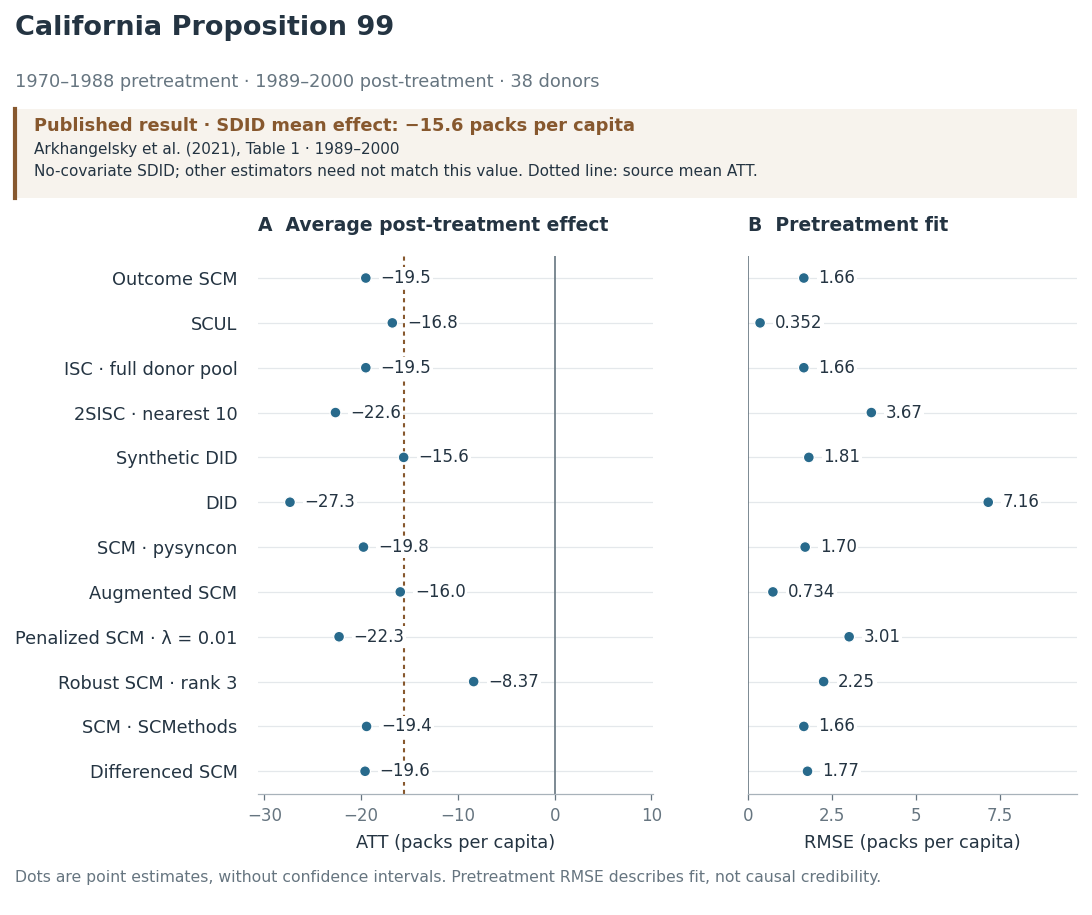

In [5]:
fig, axes = plot_comparison(
    results, labels=display_labels,
    title=figure_details['case'],
    subtitle=figure_details['periods'],
    units=figure_details['units'],
    benchmark=replace(benchmark, context=benchmark.context + (
        ' Dotted line: source mean ATT.' if benchmark.value is not None else ''
    )),
)
comparison_files = export_figure(fig, 'comparison')
comparison.to_csv(figure_dir / f'{name}-estimates.csv', float_format='%.12g')
plt.show()

## Effect paths on a common scale

Every panel shows **observed minus counterfactual**. All twelve panels
share the same horizontal and vertical scales; no extreme estimate is
clipped. The zero line denotes no estimated effect. The dashed vertical
line and shaded region identify the common treatment onset and post-period.
Shading does not represent uncertainty. Calendar spacing is preserved,
including quarterly observations. Panel labels replace repeated legends.
Ochre dotted segments, where present, mark the source's average effect
over the post-period; they are not published period-by-period trajectories.

**Download figure:** [PDF](figures/california/california-effects.pdf) · [SVG](figures/california/california-effects.svg) · [PNG](figures/california/california-effects.png)

**Literature source:** [Arkhangelsky et al. (2021), Table 1 · 1989–2000](https://arxiv.org/pdf/1812.09970v4#page=8)

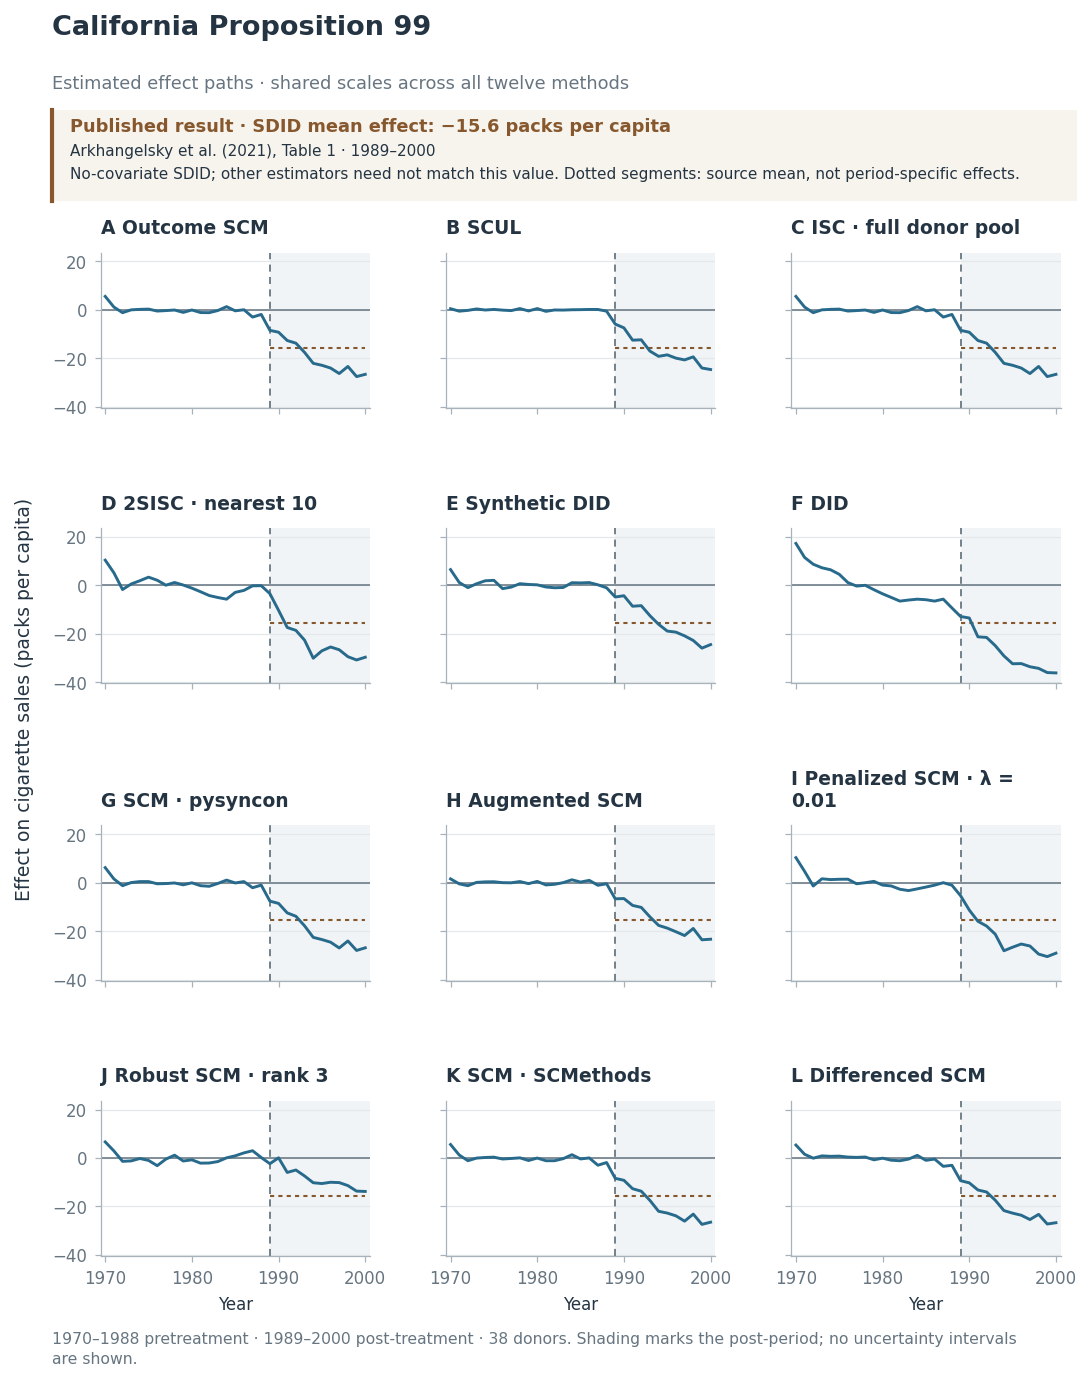

In [6]:
fig, axes = plot_effects(
    results, labels=display_labels,
    title=figure_details['case'],
    subtitle='Estimated effect paths · shared scales across all twelve methods',
    ylabel=figure_details['effect'], xlabel='Year',
    benchmark=replace(benchmark, context=benchmark.context + (
        ' Dotted segments: source mean, not period-specific effects.' if benchmark.value is not None else ''
    )),
    note=figure_details['periods'] + '. Shading marks the post-period; no uncertainty intervals are shown.',
)
effects_files = export_figure(fig, 'effects')
plt.show()

## Inspect the donor coefficients

These are the fifteen donors with the largest absolute coefficient in
any method, not an exhaustive donor list. The coefficients are not
renormalized. SCUL and some augmented/robust estimates can have negative
weights or weight sums different from one. Intercepts and SDID time
weights are separate components; this table does not represent them.

In [7]:
weights = pd.concat({label: fit.weights for label, fit in results.items()}, axis=1)
weights.loc[weights.abs().max(axis=1).sort_values(ascending=False).index].head(15).round(4)

,Outcome SCM,SCUL,ISC (full donor pool),2SISC (nearest 10),Synthetic DID,DID,pysyncon SCM,Augmented SCM,Penalized SCM (0.01),"Robust SCM (rank 3, ridge 0.1)",SyntheticControlMethods SCM,Differenced SCM
Utah,0.3939,0.2382,0.3939,0.0000,0.0415,0.0263,0.3845,0.3702,0.0000,0.0307,0.3929,0.3451
Montana,0.2319,0.1164,0.2319,0.2663,0.0451,0.0263,0.2721,0.2484,0.3753,0.0211,0.2223,0.2389
Idaho,0.0000,0.0797,0.0000,0.3551,0.0315,0.0263,0.0000,-0.0191,0.2881,0.0404,0.0000,0.0000
Tennessee,0.0000,-0.2738,0.0000,0.0000,0.0000,0.0263,0.0000,-0.0414,0.0000,-0.0536,0.0000,0.0000
Colorado,0.0148,0.0408,0.0148,0.2552,0.0575,0.0263,0.0290,0.0329,0.0000,0.0635,0.0264,0.0000
Nevada,0.2049,0.1512,0.2049,0.0000,0.1245,0.0263,0.1865,0.2020,0.0817,0.1194,0.2062,0.2192
Nebraska,0.0000,0.1872,0.0000,0.0000,0.0479,0.0263,0.0000,0.0267,0.0000,0.0171,0.0000,0.0000
Connecticut,0.1091,0.1573,0.1091,0.1234,0.0783,0.0263,0.0794,0.1512,0.1010,0.0590,0.1086,0.1567
New Mexico,0.0000,0.0519,0.0000,0.0000,0.0406,0.0263,0.0000,-0.0004,0.1539,0.0510,0.0000,0.0000
Illinois,0.0000,0.1500,0.0000,0.0000,0.0534,0.0263,0.0000,0.0502,0.0000,0.0836,0.0000,0.0000


## Interpretation, exports and reproducibility

Negative effects mean the observed outcome is below its estimated
untreated path. These are point estimates under different restrictions,
tuning choices and identifying assumptions. They are not an uncertainty
distribution. The historical reference check is distinct from the new
comparison specifications and their stated simplifications.

Each figure is exported at **7.2 inches wide** in three formats: PDF with
embedded fonts, SVG with editable text, and 300 dpi PNG. The links beside
each figure download the full export. The estimator summary is also saved
as CSV. Use vector formats for manuscripts and adjust figure size, labels
and captions through the plotting API before exporting to a journal's
requirements. Nothing depends on system fonts or an external TeX install.

`pysynth.placebo_test` provides in-space RMSPE-ratio diagnostics and a rank
p-value under exchangeability assumptions; it is not synthdid's placebo
variance estimator. The original SCUL scanner-data and ISC/costofcare
survey studies are not reproduced here. Re-run from a fresh kernel to
reproduce the source checks, estimates and figures together.